### Name: Qian Ling GitHub 
### Username: qianling-sketch
### USC ID: 7728910687

## 1. Time Series Classification Part 1

In [5]:
import os
import pandas as pd
import numpy as np

data_path = "../data/AReM"

print(os.listdir(data_path))

['bendingType.pdf', '.DS_Store', 'bending1', 'walking', 'sensorsPlacement.pdf', 'bending2', 'standing', 'sitting', 'lying', 'cycling']


### (b)

In [6]:
activities = [
    "bending1", "bending2", "cycling",
    "lying", "sitting", "standing", "walking"
]

train_files = []
test_files = []

for activity in activities:
    folder = os.path.join(data_path, activity)
    
    for file in os.listdir(folder):
        if not file.endswith(".csv"):
            continue
        
        file_num = int(file.replace("dataset", "").replace(".csv", ""))
        file_path = os.path.join(folder, file)
        
        if activity in ["bending1", "bending2"]:
            if file_num in [1, 2]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)
        else:
            if file_num in [1, 2, 3]:
                test_files.append(file_path)
            else:
                train_files.append(file_path)

print("Training instances:", len(train_files))
print("Test instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Test instances: 19
Total instances: 88


### (c)(i)

The commonly used ones include: minimum value, maximum value, mean value, median, standard deviation, variance, first/third quartiles, range, interquartile range IQR, etc.

### (ii)

In [7]:
cols = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13',
        'var_rss13', 'avg_rss23', 'var_rss23']

def extract_features(path, label):
    df = pd.read_csv(path, comment='#', header=None,
                 usecols=range(7), names=cols,
                 sep=r'[,\s]+', engine='python',
                 on_bad_lines='skip')
    df = df.dropna()
    df = df.drop(columns='time')

    feats = {}
    for i, c in enumerate(df.columns, start=1):
        x = df[c].values
        feats[f'min{i}']       = np.min(x)
        feats[f'max{i}']       = np.max(x)
        feats[f'mean{i}']      = np.mean(x)
        feats[f'median{i}']    = np.median(x)
        feats[f'std{i}']       = np.std(x, ddof=1)
        feats[f'1st_quart{i}'] = np.percentile(x, 25)
        feats[f'3rd_quart{i}'] = np.percentile(x, 75)
    feats['activity'] = label
    feats['n_rows'] = len(df)            
    return feats

train_df = pd.DataFrame([extract_features(p, p.split(os.sep)[-2]) for p in train_files])
test_df  = pd.DataFrame([extract_features(p, p.split(os.sep)[-2]) for p in test_files])

# Merge into the 88-row table in the title, with Instance ranging from 1 to 8
all_df = pd.concat([train_df, test_df], ignore_index=True)
all_df.index = range(1, len(all_df) + 1)
all_df.index.name = 'Instance'

print(train_df.shape, test_df.shape, all_df.shape)
print(all_df['n_rows'].unique())         
all_df.head()

(69, 44) (19, 44) (88, 44)
[480 479]


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity,n_rows
Instance,,,,,,,,,,,,,,,,,,,,,
1,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,0.0,1.50,0.413125,...,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83,bending1,480
2,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,0.0,1.58,0.378083,...,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87,bending1,480
3,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,...,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00,bending1,480
4,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,...,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50,bending1,480
5,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,...,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94,bending1,480


In [8]:
for p in train_files + test_files:
    features = extract_features(p, p.split(os.sep)[-2])
    if features['n_rows'] != 480:
        print(p, features['n_rows'])

../data/AReM/sitting/dataset8.csv 479


### (iii)

In [10]:
feature_cols = [c for c in all_df.columns if c not in ['activity', 'n_rows']]
X = all_df[feature_cols].values        # 88 x 42

rng = np.random.default_rng(0)
B = 2000
n = X.shape[0]

boot_std = np.empty((B, X.shape[1]))
for b in range(B):
    idx = rng.integers(0, n, n)       
    boot_std[b] = X[idx].std(axis=0, ddof=1)

std_table = pd.DataFrame({
    'std':    X.std(axis=0, ddof=1),
    'CI_5%':  np.percentile(boot_std, 5,  axis=0),
    'CI_95%': np.percentile(boot_std, 95, axis=0)
}, index=feature_cols)
std_table

,std,CI_5%,CI_95%
min1,9.569975,8.255488,10.798825
max1,4.394362,3.356895,5.275593
mean1,5.335718,4.696066,5.883307
median1,5.440054,4.786646,5.987759
std1,1.772153,1.579102,1.952310
1st_quart1,6.153590,5.587456,6.653489
3rd_quart1,5.138925,4.300110,5.826979
min2,0.000000,0.000000,0.000000
max2,5.062729,4.647263,5.418592
mean2,1.574164,1.405500,1.703020


The standard deviation of each of the 42 time-domain features was estimated across the 88 instances. A 90% bootstrap confidence interval was constructed using the 5th and 95th percentiles of the bootstrap distribution.

### (iv)

In [11]:
from sklearn.feature_selection import f_classif

nonconstant_cols = [
    c for c in feature_cols
    if all_df[c].nunique() > 1
]

F, p = f_classif(
    all_df[nonconstant_cols],
    all_df['activity']
)

rank = pd.Series(F, index=nonconstant_cols).sort_values(ascending=False)
rank.head(10)

median4       1012.029961
mean2          918.634048
3rd_quart6     860.283987
mean4          841.261961
3rd_quart2     819.386877
mean6          815.805627
median6        743.316200
3rd_quart4     702.845559
median2        564.354086
std2           461.977996
dtype: float64

Based on the ANOVA F-scores, I selected **mean, median, and third quartile** as the three most important time-domain features. These features consistently showed high discriminative power across the six time series.

## 2. Time Series Classification Part 2

### a.(i)

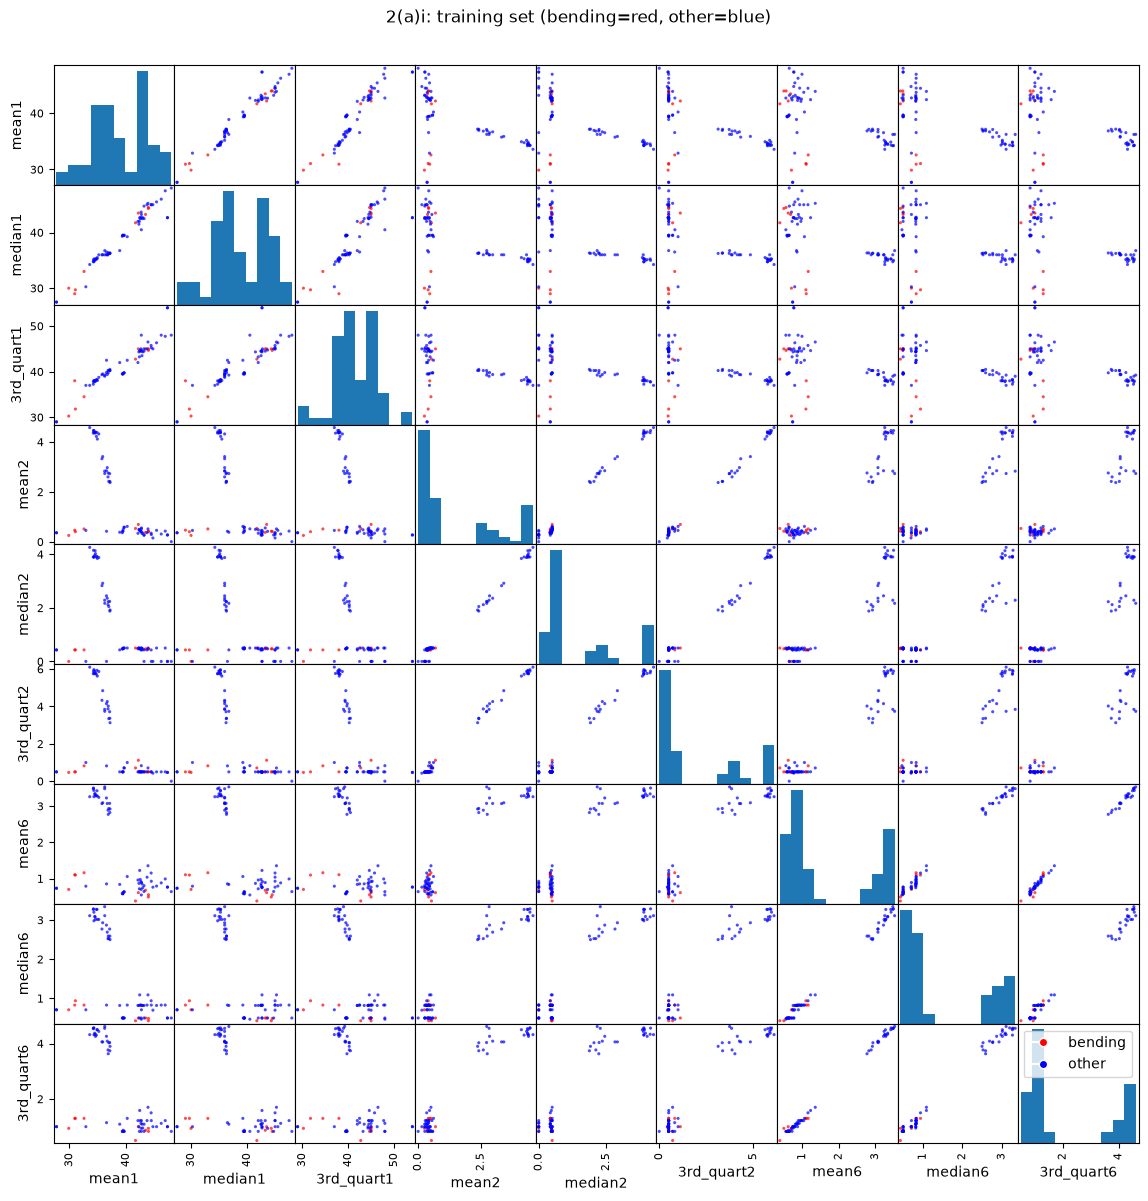

In [13]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ftypes = ['mean', 'median', '3rd_quart']
sel = [f'{t}{s}' for s in [1, 2, 6] for t in ftypes]

bending = train_df['activity'].isin(['bending1', 'bending2'])
color = bending.map({True: 'red', False: 'blue'})

pd.plotting.scatter_matrix(
    train_df[sel],
    c=color,
    figsize=(14, 14),
    alpha=0.7,
    s=20,
    diagonal='hist'
)

handles = [
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='red', label='bending'),
    Line2D([0], [0], marker='o', color='w',
           markerfacecolor='blue', label='other')
]

plt.legend(handles=handles, loc='upper right')
plt.suptitle('2(a)i: training set (bending=red, other=blue)', y=0.92)
plt.show()

The scatter plots show some separation between bending and other activities, although there is still overlap between the two classes.

### (ii)

In [18]:
def extract_features_split(df, l):
    feats = {}
    idx_splits = np.array_split(np.arange(len(df)), l)     
    for p, idx in enumerate(idx_splits, start=1):
        part = df.iloc[idx]                                 
        for i, c in enumerate(part.columns, start=1):
            x = part[c].values
            feats[f'min{i}_p{p}']       = np.min(x)
            feats[f'max{i}_p{p}']       = np.max(x)
            feats[f'mean{i}_p{p}']      = np.mean(x)
            feats[f'median{i}_p{p}']    = np.median(x)
            feats[f'std{i}_p{p}']       = np.std(x, ddof=1)
            feats[f'1st_quart{i}_p{p}'] = np.percentile(x, 25)
            feats[f'3rd_quart{i}_p{p}'] = np.percentile(x, 75)
    return feats

(69, 86)


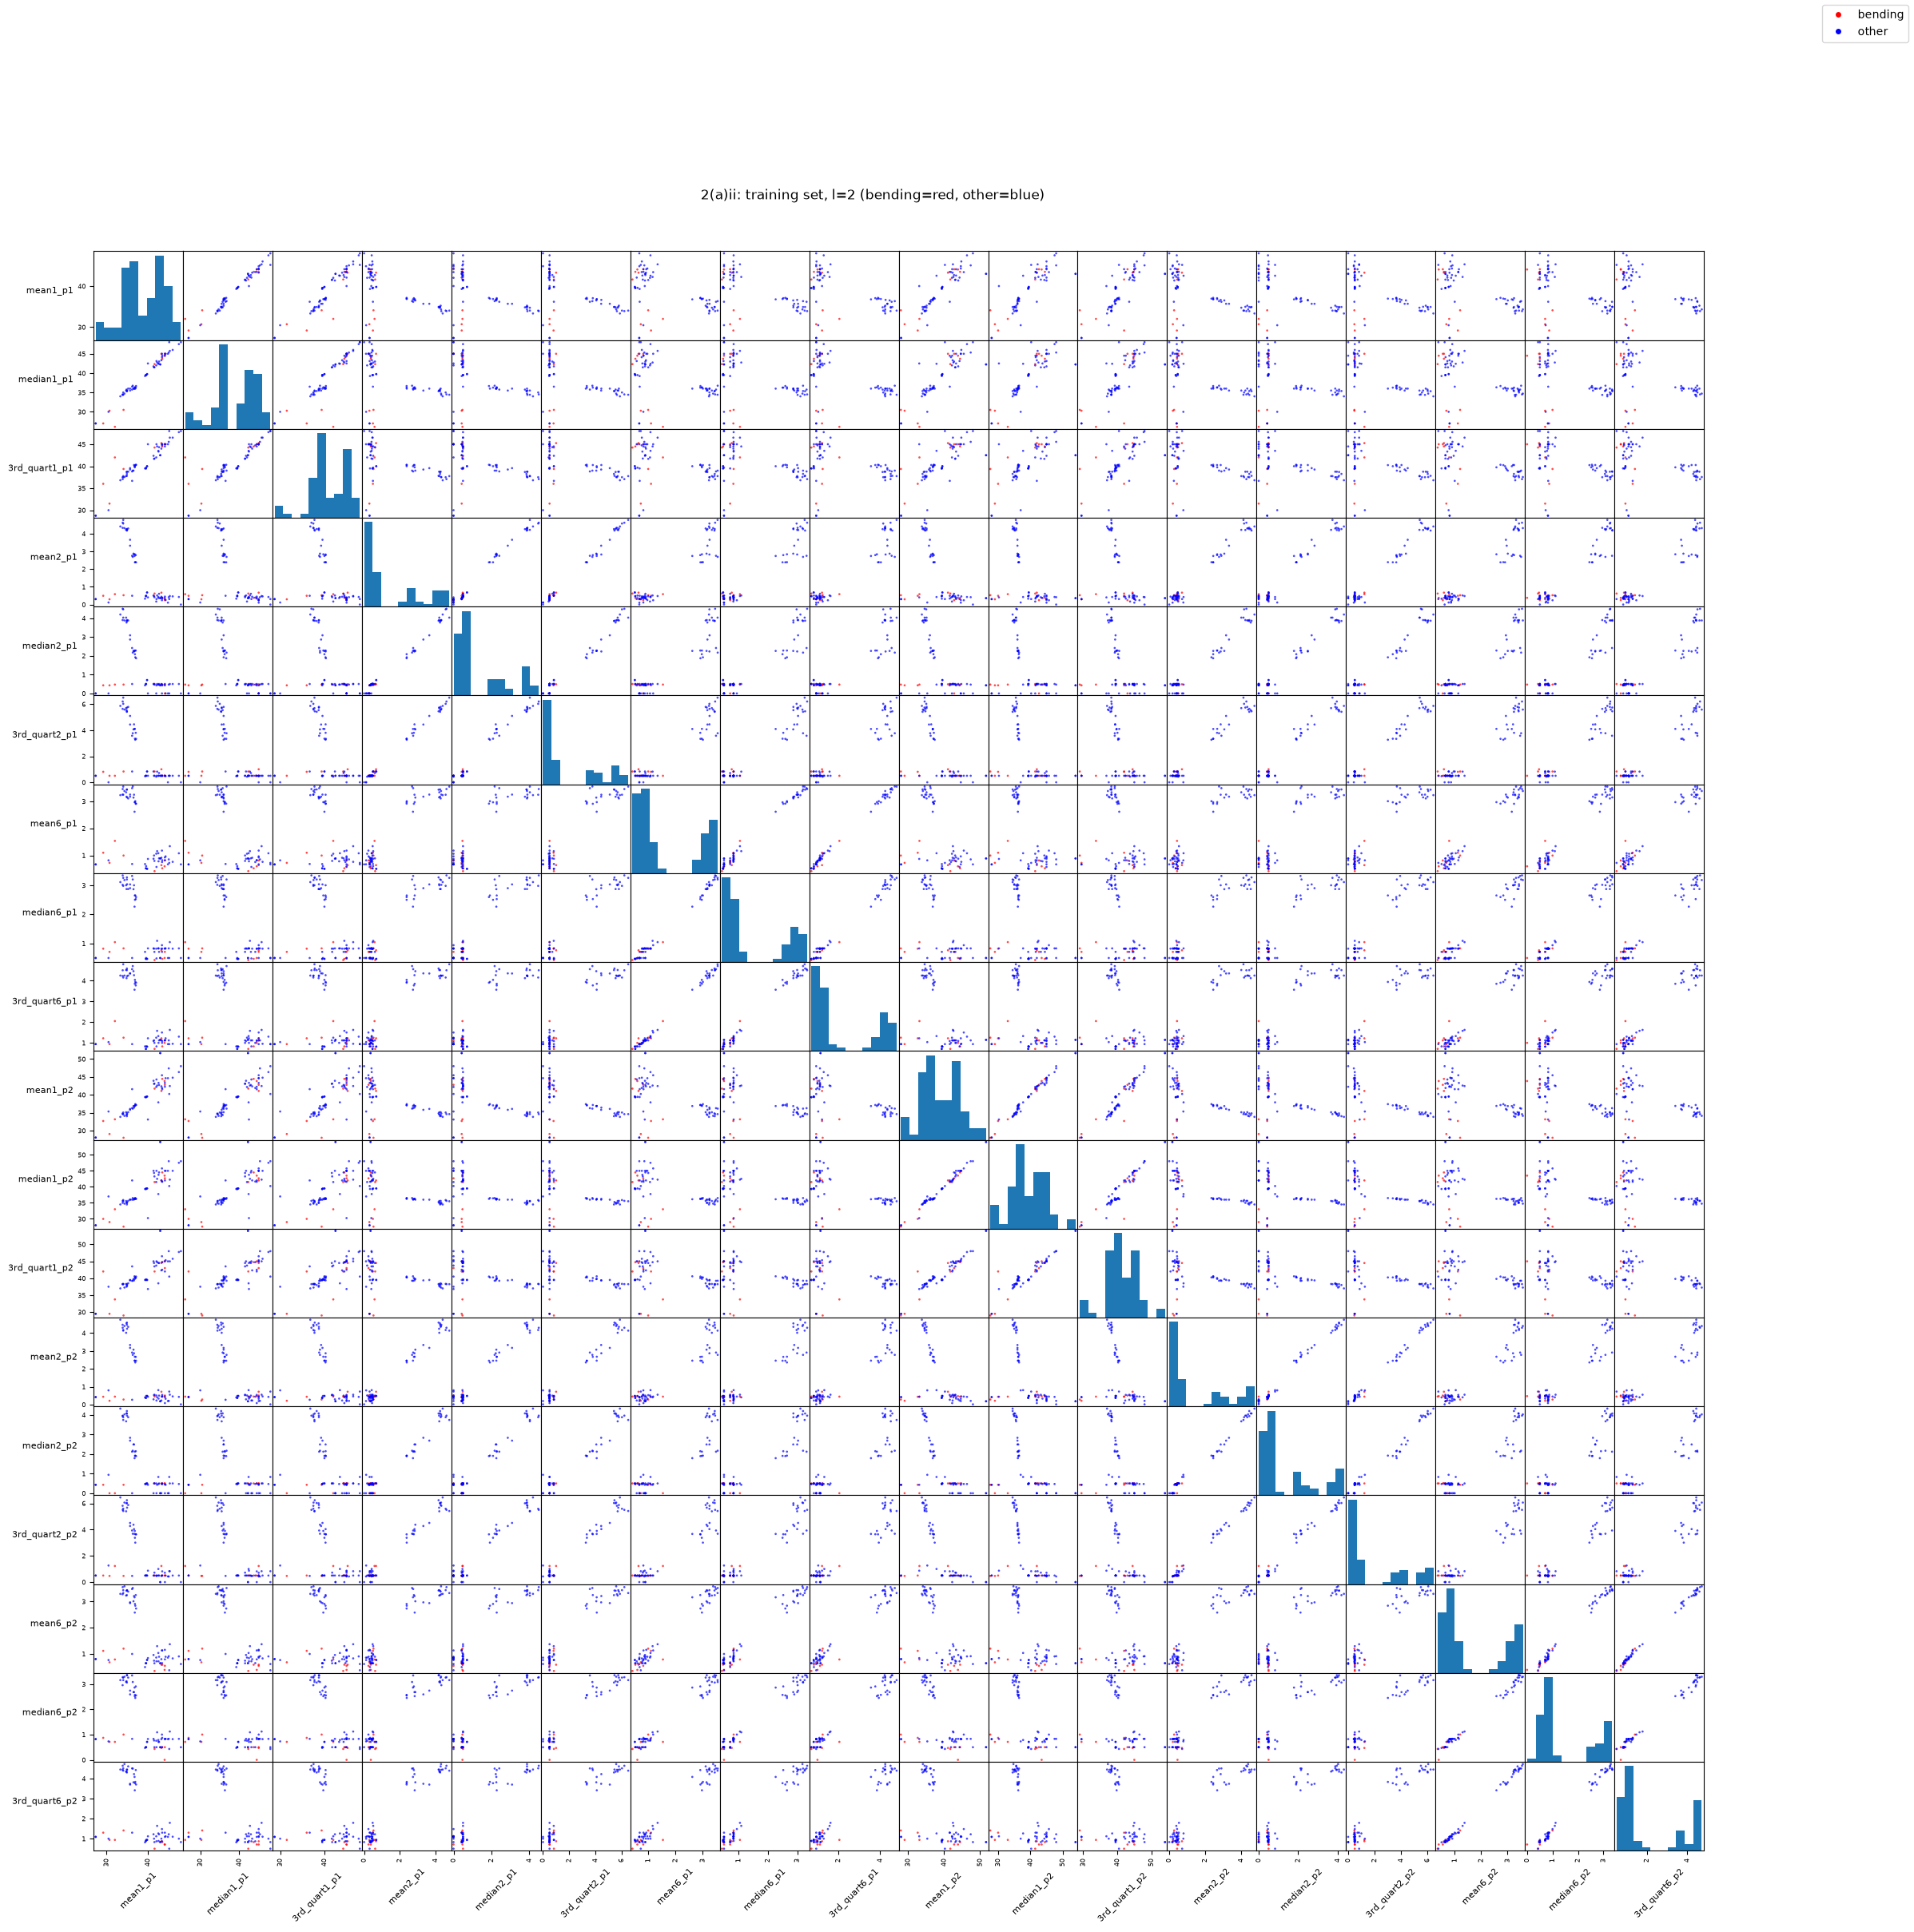

In [22]:
train_l2 = build_dataset(train_files, l=2)
print(train_l2.shape)    

sel2 = [f'{t}{s}_p{p}' for p in [1, 2] for s in [1, 2, 6] for t in ftypes] 
color2 = train_l2['bending'].map({1: 'red', 0: 'blue'})

axes = pd.plotting.scatter_matrix(train_l2[sel2], c=color2, figsize=(26, 26),
                           alpha=0.7, s=15, diagonal='hist')

for ax in axes.ravel():
    ax.xaxis.label.set_fontsize(8)
    ax.yaxis.label.set_fontsize(8)
    ax.xaxis.label.set_rotation(45)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha('right')
    ax.tick_params(labelsize=6)
plt.gcf().legend(handles=handles, loc='upper right')
plt.suptitle('2(a)ii: training set, l=2 (bending=red, other=blue)', y=0.91)
plt.show()

There is no considerable difference compared with 2(a)i. For each feature, the first-half (p1) and second-half (p2) values are almost perfectly correlated, so splitting adds little new information. Splitting doubles the number of features (9 to 18), but the classes are still not clearly separable.

### (iii)

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import RFE

train_l1 = build_dataset(train_files, l=1)

X = train_l1.drop(columns=['activity', 'bending'])
y = train_l1['bending']

print(X.shape)
print(y.value_counts())


(69, 42)
bending
0    60
1     9
Name: count, dtype: int64


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def make_pipe(p):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('rfe', RFE(
            LogisticRegression(C=1e6, max_iter=2000),
            n_features_to_select=p,
            step=0.1
        )),
        ('clf', LogisticRegression(C=1e6, max_iter=2000))
    ])

results = []
for l in range(1, 21):
    data_l = build_dataset(train_files, l=l)
    X_l = data_l.drop(columns=['activity', 'bending'])
    y_l = data_l['bending']
    n_feat = X_l.shape[1]
    p_grid = sorted(set([2, 5, 10, 20, 40, 80]) & set(range(1, n_feat + 1)))
    for p in p_grid:
        acc = cross_val_score(make_pipe(p), X_l, y_l, cv=skf,
                              scoring='accuracy', n_jobs=-1).mean()
        results.append({'l': l, 'p': p, 'cv_acc': acc})  

res_df = pd.DataFrame(results).sort_values('cv_acc', ascending=False)
res_df.head(10)

,l,p,cv_acc
31,6,10,0.971429
116,20,20,0.971429
77,14,2,0.971429
74,13,20,0.970330
3,1,20,0.957143
62,11,20,0.957143
108,19,5,0.957143
55,10,10,0.957143
54,10,5,0.957143
109,19,10,0.957143


In [28]:
best = res_df.iloc[0]
print(best)
best_l, best_p = int(best['l']), int(best['p'])

l          6.000000
p         10.000000
cv_acc     0.971429
Name: 31, dtype: float64


The best pair selected by 5-fold stratified cross-validation is l, p) = (6, 10), with a mean CV accuracy of 0.9714.

The wrong way is to select features on the whole training set before cross-validation, because information from the validation folds would leak into the feature selection process and make the CV accuracy overly optimistic.

The right way is to perform feature selection inside each fold using only the training portion of that fold, and then evaluate the model on the held-out portion. I used a pipeline containing standardization, RFE, and logistic regression so that feature selection is performed separately within each fold.

### (iv)

In [29]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

data_best = build_dataset(train_files, l=best_l)

X_best = data_best.drop(columns=['activity', 'bending'])
y_best = data_best['bending']

final_pipe = make_pipe(best_p)
final_pipe.fit(X_best, y_best)

y_pred = final_pipe.predict(X_best)
y_prob = final_pipe.predict_proba(X_best)[:, 1]

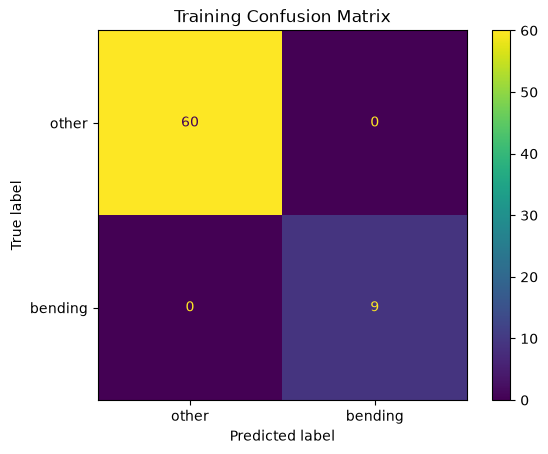

[[60  0]
 [ 0  9]]


In [30]:
cm = confusion_matrix(y_best, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['other', 'bending']
)

disp.plot()
plt.title('Training Confusion Matrix')
plt.show()

print(cm)

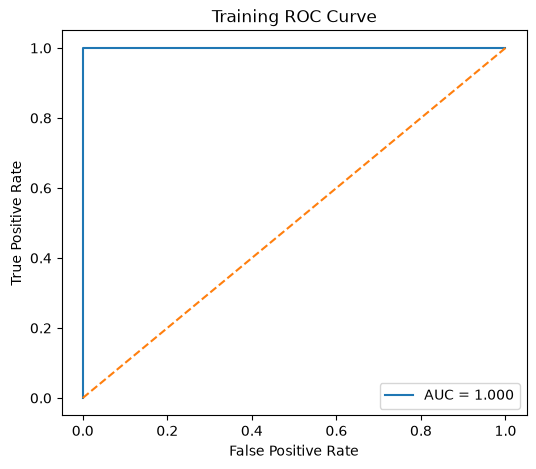

AUC: 1.0


In [31]:
fpr, tpr, thresholds = roc_curve(y_best, y_prob)
auc = roc_auc_score(y_best, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], '--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Training ROC Curve')
plt.legend()
plt.show()

print('AUC:', auc)

In [32]:
rfe = final_pipe.named_steps['rfe']

selected_features = X_best.columns[rfe.support_]

print('Selected features:')
print(list(selected_features))


clf = final_pipe.named_steps['clf']

coef_df = pd.DataFrame({
    'feature': selected_features,
    'beta': clf.coef_[0]
})

coef_df

Selected features:
['max5_p1', 'mean5_p1', 'std3_p2', 'min5_p2', 'max5_p2', 'median1_p4', '1st_quart4_p5', '3rd_quart3_p6', 'max5_p6', 'max6_p6']


,feature,beta
0,max5_p1,2.475185
1,mean5_p1,3.484275
2,std3_p2,0.372924
3,min5_p2,1.993411
4,max5_p2,2.117078
5,median1_p4,-2.778846
6,1st_quart4_p5,-2.515320
7,3rd_quart3_p6,-2.116089
8,max5_p6,1.450625
9,max6_p6,-0.991123


In [ ]:
import statsmodels.api as sm

# Get the standardized data
scaler = final_pipe.named_steps['scaler']
X_scaled = scaler.transform(X_best)

# Keep only the features selected by RFE
X_selected = X_scaled[:, rfe.support_]

# Add intercept
X_sm = sm.add_constant(X_selected)

# Fit logistic regression using statsmodels
logit_model = sm.Logit(y_best.values, X_sm)
result = logit_model.fit()

result.summary()

The selected features perfectly separate the two classes on the training set. Therefore, fitting an unregularized logistic regression with 'statsmodels'results in perfect separation, and reliable p-values cannot be obtained.

### (v)

[[15  0]
 [ 1  3]]
Test accuracy: 0.9473684210526315
CV accuracy:   0.9714285714285715


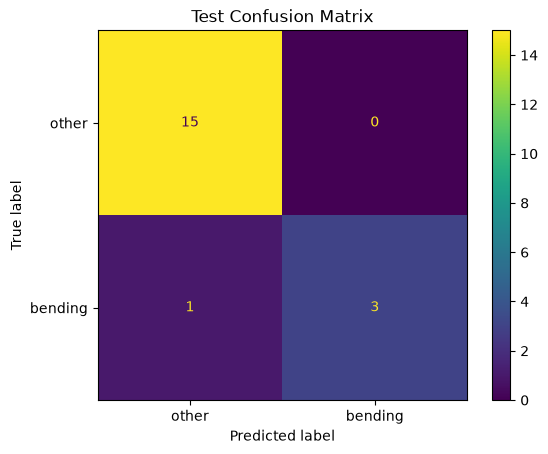

Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474
CV error: 0.02857142857142847


In [36]:
test_best = build_dataset(test_files, l=best_l)
X_te = test_best.drop(columns=['activity', 'bending'])
y_te = test_best['bending']

y_te_pred = final_pipe.predict(X_te)
y_te_prob = final_pipe.predict_proba(X_te)[:, 1]

cm_te = confusion_matrix(y_te, y_te_pred)
print(cm_te)
print('Test accuracy:', (y_te_pred == y_te).mean())
print('CV accuracy:  ', best['cv_acc'])

ConfusionMatrixDisplay(cm_te, display_labels=['other', 'bending']).plot()
plt.title('Test Confusion Matrix')
plt.show()

test_acc = (y_te_pred == y_te).mean()
test_error = 1 - test_acc
cv_error = 1 - best['cv_acc']

print('Test accuracy:', test_acc)
print('Test error:', test_error)
print('CV error:', cv_error)

The test error is 0.0526 (5.26%), while the cross-validation error is approximately 0.0286 (2.86%). The test error is slightly higher than the cross-validation error, but both are low, indicating good classification
performance.

### (vi)

Yes, the two classes appear to be linearly separable on the training set. The training confusion matrix shows perfect classification and the training AUC is 1.0. In addition, statsmodels reports perfect separation when fitting the logistic regression model, so the coefficient estimates and p-values become unstable and cannot be reliably computed.

### (vii)

In [37]:
rng = np.random.default_rng(0)

idx_pos = np.where(y_best.values == 1)[0]        
idx_neg = np.where(y_best.values == 0)[0]      
idx_neg_s = rng.choice(idx_neg, size=len(idx_pos), replace=False)  

idx_cc = np.concatenate([idx_pos, idx_neg_s])
X_cc = X_best.iloc[idx_cc]
y_cc = y_best.iloc[idx_cc]
print(y_cc.value_counts())

# Perform standardization + RFE + logistic regression on the balance set
cc_pipe = make_pipe(best_p).fit(X_cc, y_cc)

# Intercept correction
pi1, pi0 = y_best.mean(), 1 - y_best.mean()      
n1, n0 = 0.5, 0.5                               
shift = np.log(pi1 / pi0) - np.log(n1 / n0)

clf_cc = cc_pipe.named_steps['clf']
print('intercept before:', clf_cc.intercept_[0])
clf_cc.intercept_ = clf_cc.intercept_ + shift
print('intercept after: ', clf_cc.intercept_[0], '(shift =', round(shift, 3), ')')

bending
1    9
0    9
Name: count, dtype: int64
intercept before: 0.7687030673067115
intercept after:  -1.1284169175791698 (shift = -1.897 )


Train (original, 69) 
 [[58  2]
 [ 0  9]]  accuracy = 0.971
Test (19) 
 [[14  1]
 [ 1  3]]  accuracy = 0.895


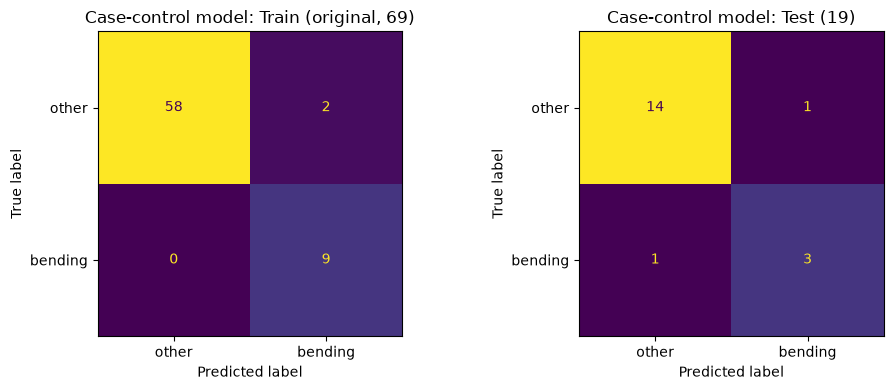

In [38]:
from sklearn.metrics import accuracy_score

sets = {'Train (original, 69)': (X_best, y_best), 'Test (19)': (X_te, y_te)}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (Xs, ys)) in zip(axes, sets.items()):
    pred = cc_pipe.predict(Xs)
    cm_ = confusion_matrix(ys, pred)
    print(name, '\n', cm_, ' accuracy =', round(accuracy_score(ys, pred), 3))
    ConfusionMatrixDisplay(cm_, display_labels=['other', 'bending']).plot(ax=ax, colorbar=False)
    ax.set_title(f'Case-control model: {name}')
plt.tight_layout()
plt.show()


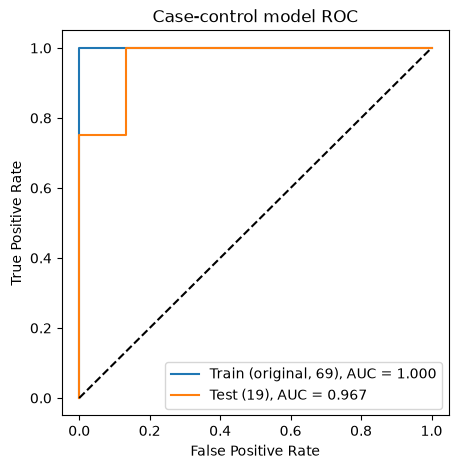

In [39]:
plt.figure(figsize=(5, 5))
for name, (Xs, ys) in sets.items():
    prob = cc_pipe.predict_proba(Xs)[:, 1]
    fpr_, tpr_, _ = roc_curve(ys, prob)
    plt.plot(fpr_, tpr_, label=f'{name}, AUC = {roc_auc_score(ys, prob):.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Case-control model ROC')
plt.legend()
plt.show()


In [41]:
print('Original model test AUC:', roc_auc_score(y_te, y_te_prob))

Original model test AUC: 1.0


There is a clear class imbalance in the training set, with 9 bending and 60 other instances. The case-control model reduces this imbalance by using 9 instances from each class. Its test accuracy is 0.895 and test AUC is 0.967, compared with 0.947 accuracy and 1.000 AUC for the original model. The intercept was corrected to account for the changed class proportions.

### b.(i)

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

C_grid = [0.01, 0.1, 1, 10, 100]
results_l1 = []

for l in range(1, 21):
    data_l = build_dataset(train_files, l=l)
    X_l = data_l.drop(columns=['activity', 'bending'])
    y_l = data_l['bending']

    for C in C_grid:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(
                solver='liblinear',
                C=C,
                l1_ratio=1,
                max_iter=2000
            ))
        ])

        acc = cross_val_score(
            pipe, X_l, y_l,
            cv=skf,
            scoring='accuracy'
        ).mean()

        results_l1.append({
            'l': l,
            'C': C,
            'cv_acc': acc
        })

l1_df = pd.DataFrame(results_l1).sort_values(
    'cv_acc', ascending=False
)

l1_df.head(10)

,l,C,cv_acc
89,18,100.0,0.985714
93,19,10.0,0.985714
87,18,1.0,0.971429
57,12,1.0,0.971429
8,2,10.0,0.971429
88,18,10.0,0.971429
2,1,1.0,0.970330
12,3,1.0,0.957143
92,19,1.0,0.957143
53,11,10.0,0.957143


In [45]:
best_l1 = l1_df.iloc[0]

best_l_l1 = int(best_l1['l'])
best_C_l1 = float(best_l1['C'])

print('Best l:', best_l_l1)
print('Best C:', best_C_l1)
print('Best CV accuracy:', best_l1['cv_acc'])

Best l: 18
Best C: 100.0
Best CV accuracy: 0.9857142857142858


In [46]:
data_l1 = build_dataset(train_files, l=best_l_l1)
X_l1 = data_l1.drop(columns=['activity', 'bending'])
y_l1 = data_l1['bending']

final_l1 = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(
        solver='liblinear',
        C=best_C_l1,
        l1_ratio=1,
        max_iter=2000
    ))
])

final_l1.fit(X_l1, y_l1)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](756,)","['min1_p1','max1_p1','mean1_p1',...,'std6_p18','1st_quart6_p18', '3rd_quart6_p18']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,756
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [47]:
coef = final_l1.named_steps['clf'].coef_[0]

selected = X_l1.columns[coef != 0]

print('Number of selected features:', len(selected))
print('Selected features:')
print(list(selected))

Number of selected features: 40
Selected features:
['max5_p1', 'min5_p2', 'max1_p3', 'min5_p3', 'max5_p3', 'mean5_p3', 'median5_p3', '1st_quart5_p3', '3rd_quart5_p3', 'std3_p4', 'max2_p5', 'std3_p5', 'min5_p5', 'min3_p7', 'mean3_p7', 'median3_p7', 'std3_p8', 'max1_p9', 'max1_p10', 'std1_p10', '3rd_quart1_p10', 'mean1_p11', 'median1_p11', '3rd_quart1_p11', 'max1_p12', 'max1_p13', '3rd_quart1_p13', 'max4_p13', '1st_quart4_p13', '3rd_quart4_p13', 'std5_p14', 'max6_p14', 'std6_p14', 'min3_p16', '3rd_quart3_p16', 'min5_p16', 'min5_p17', 'std5_p17', 'max6_p17', 'std5_p18']


[[15  0]
 [ 1  3]]
Test accuracy: 0.9473684210526315
CV accuracy:   0.9857142857142858
Test AUC:      0.9500000000000001


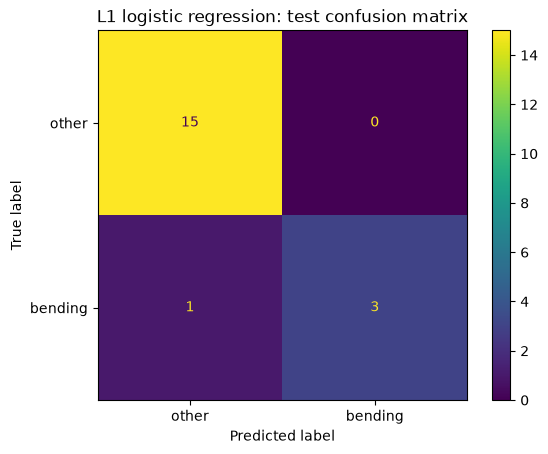

In [48]:
test_l1 = build_dataset(test_files, l=best_l_l1)
X_te1 = test_l1.drop(columns=['activity', 'bending'])
y_te1 = test_l1['bending']

pred1 = final_l1.predict(X_te1)
prob1 = final_l1.predict_proba(X_te1)[:, 1]

cm1 = confusion_matrix(y_te1, pred1)
print(cm1)
print('Test accuracy:', accuracy_score(y_te1, pred1))
print('CV accuracy:  ', best_l1['cv_acc'])
print('Test AUC:     ', roc_auc_score(y_te1, prob1))
ConfusionMatrixDisplay(cm1, display_labels=['other', 'bending']).plot()
plt.title('L1 logistic regression: test confusion matrix')
plt.show()

Using 5-fold cross-validation, the best parameters were \(l=18\) and \(C=100\), with a CV accuracy of 0.9857. The final L1-penalized logistic regression selected 40 non-zero features out of 756 features. The test accuracy was 0.9474 and the test AUC was 0.95.

### (ii)

The L1-penalized model had a higher cross-validation accuracy (0.9857 vs. 0.9714), while both models had the same test accuracy (0.9474). Therefore, their test performance was similar, although L1 performed slightly better in cross-validation. L1 was also easier to implement because it performs variable selection automatically by shrinking some coefficients to zero.

### c.(i)

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf_multi = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)

C_grid = [0.1, 1, 10]
results_multi = []

for l in range(1, 21):
    data_l = build_dataset(train_files, l=l)

    X_l = data_l.drop(columns=['activity', 'bending'])
    y_l = data_l['activity']

    for C in C_grid:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', LogisticRegression(
                solver='saga',
                C=C,
                l1_ratio=1,
                max_iter=5000
            ))
        ])

        acc = cross_val_score(
            pipe,
            X_l,
            y_l,
            cv=skf_multi,  
            scoring='accuracy',
            n_jobs=-1
        ).mean()

        results_multi.append({
            'l': l,
            'C': C,
            'cv_acc': acc
        })

multi_df = pd.DataFrame(results_multi).sort_values(
    'cv_acc', ascending=False
)

multi_df.head(10)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max

,l,C,cv_acc
2,1,10.0,0.868464
1,1,1.0,0.854575
5,2,10.0,0.840686
14,5,10.0,0.795752
29,10,10.0,0.795752
59,20,10.0,0.782680
52,18,1.0,0.781863
10,4,1.0,0.781046
4,2,1.0,0.768791
11,4,10.0,0.767974


In [55]:
best_multi = multi_df.iloc[0]

best_l_multi = int(best_multi['l'])
best_C_multi = float(best_multi['C'])

print('Best l:', best_l_multi)
print('Best C:', best_C_multi)
print('Best CV accuracy:', best_multi['cv_acc'])

Best l: 1
Best C: 10.0
Best CV accuracy: 0.8684640522875816


In [56]:
best_multi = multi_df.iloc[0]

best_l_multi = int(best_multi['l'])
best_C_multi = float(best_multi['C'])

print('Best l:', best_l_multi)
print('Best C:', best_C_multi)
print('Best CV accuracy:', best_multi['cv_acc'])

train_multi = build_dataset(train_files, l=best_l_multi)
X_train_multi = train_multi.drop(columns=['activity', 'bending'])
y_train_multi = train_multi['activity']

final_multi = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(
        solver='saga',
        C=best_C_multi,
        l1_ratio=1,
        max_iter=5000
    ))
])

final_multi.fit(X_train_multi, y_train_multi)

Best l: 1
Best C: 10.0
Best CV accuracy: 0.8684640522875816


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](7,)","['bending1','bending2','cycling',...,'sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['min1_p1','max1_p1','mean1_p1',...,'std6_p1','1st_quart6_p1', '3rd_quart6_p1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Test accuracy: 0.9473684210526315
Test error: 0.052631578947368474


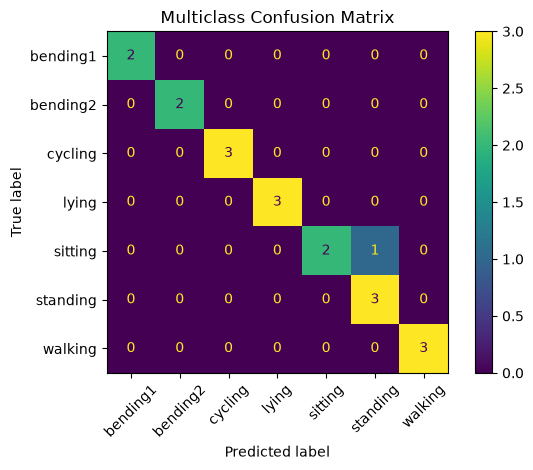

In [58]:
test_multi = build_dataset(test_files, l=best_l_multi)
X_test_multi = test_multi.drop(columns=['activity', 'bending'])
y_test_multi = test_multi['activity']

pred_multi = final_multi.predict(X_test_multi)

test_acc = accuracy_score(y_test_multi, pred_multi)
test_error = 1 - test_acc

print('Test accuracy:', test_acc)
print('Test error:', test_error)

ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    pred_multi,
    xticks_rotation=45
)

plt.title('Multiclass Confusion Matrix')
plt.tight_layout()
plt.show()

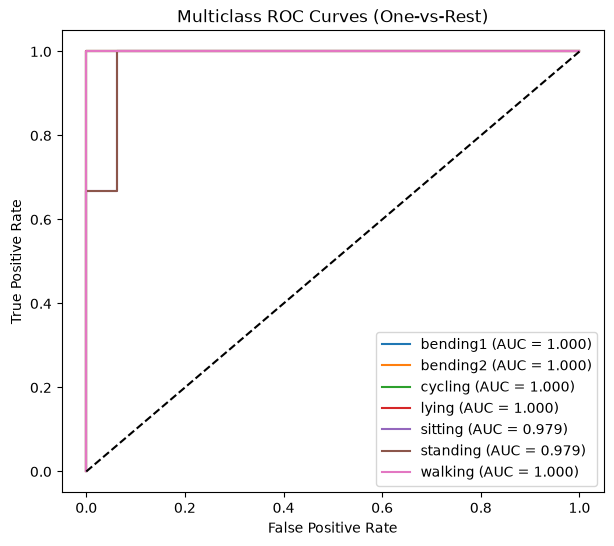

In [59]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

prob_multi = final_multi.predict_proba(X_test_multi)
classes = final_multi.named_steps['clf'].classes_

y_bin = label_binarize(y_test_multi, classes=classes)

plt.figure(figsize=(7, 6))

for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], prob_multi[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves (One-vs-Rest)')
plt.legend()
plt.show()

The best model was obtained with \(l=1\) and \(C=10\), with a cross-validation accuracy of 0.8685. I used 4-fold stratified cross-validation instead of 5-fold because the least populated activity class has only 4 training instances. The final model achieved a test accuracy of 0.9474, corresponding to a test error of 0.0526. The confusion matrix shows that only one sitting instance was misclassified as standing. The one-vs-rest ROC curves also show strong performance, with AUC = 1.000 for most classes and 0.979 for sitting and standing.

### (ii)

Gaussian NB test accuracy: 0.8947368421052632
Gaussian NB test error: 0.10526315789473684


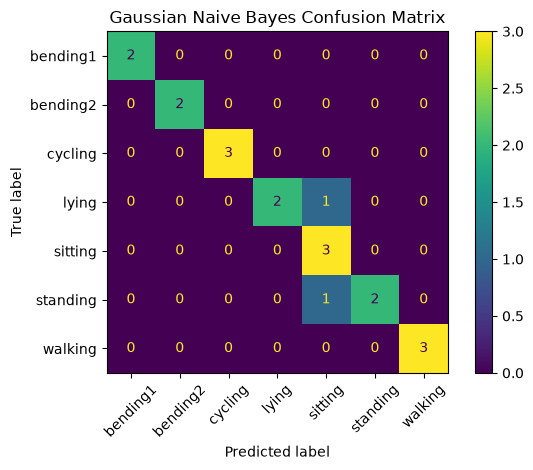

In [60]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

train_nb = build_dataset(train_files, l=best_l_multi)
test_nb = build_dataset(test_files, l=best_l_multi)

X_train_nb = train_nb.drop(columns=['activity', 'bending'])
y_train_nb = train_nb['activity']

X_test_nb = test_nb.drop(columns=['activity', 'bending'])
y_test_nb = test_nb['activity']

gnb = GaussianNB()
gnb.fit(X_train_nb, y_train_nb)

pred_gnb = gnb.predict(X_test_nb)

gnb_acc = accuracy_score(y_test_nb, pred_gnb)
gnb_error = 1 - gnb_acc

print('Gaussian NB test accuracy:', gnb_acc)
print('Gaussian NB test error:', gnb_error)

ConfusionMatrixDisplay.from_predictions(
    y_test_nb,
    pred_gnb,
    xticks_rotation=45
)

plt.title('Gaussian Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.show()

Multinomial NB test accuracy: 0.7894736842105263
Multinomial NB test error: 0.21052631578947367


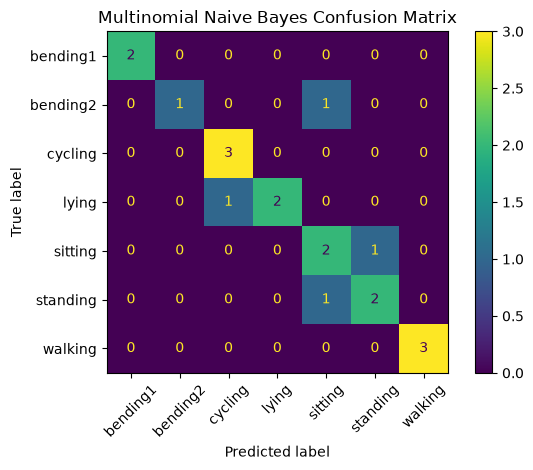

In [61]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler

multi_nb = Pipeline([
    ('scaler', MinMaxScaler()),
    ('clf', MultinomialNB())
])

multi_nb.fit(X_train_nb, y_train_nb)

pred_mnb = multi_nb.predict(X_test_nb)

mnb_acc = accuracy_score(y_test_nb, pred_mnb)
mnb_error = 1 - mnb_acc

print('Multinomial NB test accuracy:', mnb_acc)
print('Multinomial NB test error:', mnb_error)

ConfusionMatrixDisplay.from_predictions(
    y_test_nb,
    pred_mnb,
    xticks_rotation=45
)

plt.title('Multinomial Naive Bayes Confusion Matrix')
plt.tight_layout()
plt.show()

Gaussian NB (test error 0.105) outperforms Multinomial NB (0.211). The features are continuous, which fits the Gaussian assumption, whereas the multinomial model is designed for count data, and required rescaling the features to [0, 1]. Both models mostly confuse sitting with standing.

### (iii)

The L1-penalized logistic regression performs best, with a test error of 0.0526, compared with 0.1053 for Gaussian Naive Bayes and 0.2105 for Multinomial Naive Bayes. Therefore, L1-penalized logistic regression is the best method for multi-class classification in this problem.

### 3. ISLR, 4.8.3

For class $k$,

$$X \sim N(\mu_k, \sigma_k^2)$$

By Bayes' theorem, the posterior probability of class $k$ is

$$p_k(x)=\frac{\pi_k f_k(x)}{\sum_{l=1}^{K}\pi_l f_l(x)},\qquad f_k(x)=\frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$$

The Bayes classifier assigns an observation to the class with the largest $p_k(x)$. The denominator is the same for all $k$, so this is equivalent to maximizing

$$\pi_k f_k(x).$$

Taking the logarithm (which is monotonically increasing) and dropping the constant $-\log\sqrt{2\pi}$, which does not depend on $k$, the discriminant function is

$$\delta_k(x)=\log(\pi_k)-\log(\sigma_k)-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the squared term,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\log(\sigma_k)+\log(\pi_k).$$

Since $\sigma_k^2$ is different for each class, the coefficient of $x^2$ is also different for each class. Therefore, the quadratic term cannot be canceled when comparing classes.

For two classes, the decision boundary $\delta_1(x)=\delta_2(x)$ is

$$\left(-\frac{1}{2\sigma_1^2}+\frac{1}{2\sigma_2^2}\right)x^2+\left(\frac{\mu_1}{\sigma_1^2}-\frac{\mu_2}{\sigma_2^2}\right)x+(c_1-c_2)=0,$$

where $c_k=-\dfrac{\mu_k^2}{2\sigma_k^2}-\log\sigma_k+\log\pi_k$. If $\sigma_1^2\neq\sigma_2^2$, the coefficient of $x^2$ is nonzero, so this is a quadratic equation in $x$.

Thus, the Bayes classifier has a quadratic decision boundary rather than a linear one.

### 3. ISLR, 4.8.7

For the dividend class,

$$\mu_1=10,\quad \pi_1=0.8,$$

and for the no-dividend class,

$$\mu_0=0,\quad \pi_0=0.2.$$

The common variance is

$$\sigma^2=36.$$

Using Bayes' theorem,

$$P(Y=\text{Yes}\mid X=4)=\frac{\pi_1 f_1(4)}{\pi_1 f_1(4)+\pi_0 f_0(4)}.$$

Since

$$f_1(4)=\frac{1}{\sqrt{72\pi}}\exp\left(-\frac{(4-10)^2}{72}\right)=\frac{1}{\sqrt{72\pi}}e^{-1/2},$$

and

$$f_0(4)=\frac{1}{\sqrt{72\pi}}\exp\left(-\frac{(4-0)^2}{72}\right)=\frac{1}{\sqrt{72\pi}}e^{-2/9},$$

we obtain

$$P(Y=\text{Yes}\mid X=4)=\frac{0.8e^{-1/2}}{0.8e^{-1/2}+0.2e^{-2/9}}\approx 0.752.$$

Therefore, the probability that the company will issue a dividend is approximately 75.2%.